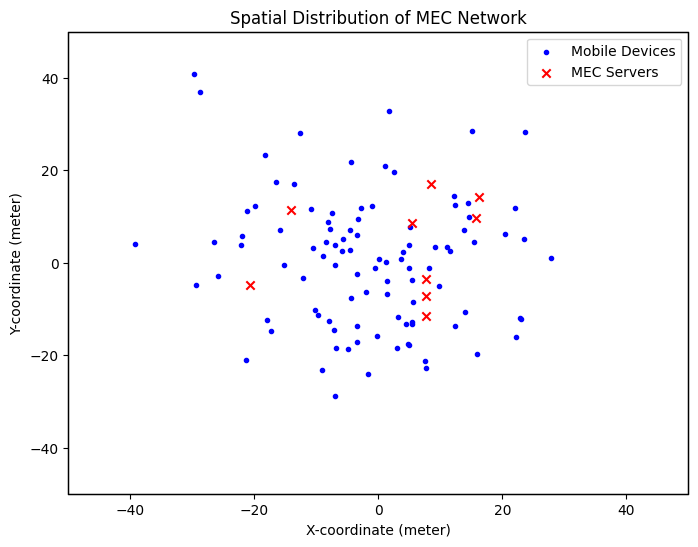


--- Simulation Summary DataFrame ---
   Time_Slot  Cost_Objective  Total_Tasks_Offloaded  Avg_Device_Energy_mJ  \
0          0    3.900000e+07                    5.0              0.044938   
1          1    5.400001e+07                   17.0              0.082415   
2          2             inf                    0.0              0.128121   
3          3             inf                    0.0              0.180762   
4          4             inf                    0.0              0.236334   
5          5             inf                    0.0              0.288005   
6          6             inf                    0.0              0.337209   
7          7             inf                    0.0              0.386696   
8          8             inf                    0.0              0.431063   
9          9             inf                    0.0              0.479118   

   Total_Device_Queue_Length  Total_MEC_Queue_Length  
0                       39.0                     0.0  
1   

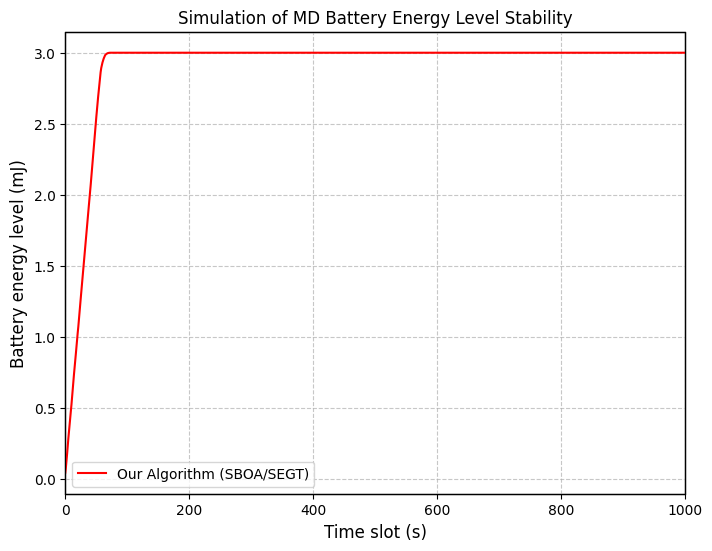

   Device_0_Energy  Device_1_Energy  Device_2_Energy  Device_3_Energy  \
0         0.005023         0.007290         0.040287         0.029529   
1         0.034214         0.027509         0.088547         0.051132   
2         0.100626         0.070168         0.177459         0.135655   
3         0.152635         0.110238         0.229602         0.213554   
4         0.214444         0.116981         0.276074         0.274500   

   Device_4_Energy  Device_5_Energy  Device_6_Energy  Device_7_Energy  \
0         0.023238         0.028100         0.080348         0.092923   
1         0.119966         0.099613         0.176062         0.135633   
2         0.172509         0.168764         0.264397         0.185205   
3         0.206520         0.186634         0.322890         0.251725   
4         0.248705         0.188547         0.421442         0.288437   

   Device_8_Energy  Device_9_Energy  ...  Device_90_Energy  Device_91_Energy  \
0         0.040510         0.090611  ...  

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy.special import factorial

USE_OPTIMIZATION = True
USE_QUEUE_MODEL = True

NUM_DEVICES = 100
NUM_SERVERS = 10
TIME_SLOTS = 100

# Energy (mJ)
ENERGY_MIN = 0.02
ENERGY_MAX = 2.0
MAX_HARVEST = 0.1

# Task characteristics
TASK_SIZE_BITS = 1e5  # 100 kbits
TASK_CPU_CYCLES = 1e8  # 100 Mcycles
TASK_PROB = 0.5

# Device computation
DEVICE_CPU_FREQ = 1e9  # 1 GHz
DEVICE_CPU_POWER = 0.5  # Watts
SLOT_DURATION = 0.1  # 100 ms per slot

# MEC server computation
MEC_CPU_FREQ = 10e9  # 10 GHz per server
MEC_CPU_POWER = 5.0  # Watts
SERVICE_RATE = 5.0  # tasks per slot per server (μ)

# Communication
BANDWIDTH = 10e6  # 10 MHz
NOISE_POWER = 1e-13  # -100 dBm
TX_POWER = 0.1  # 0.1 W
CHANNEL_GAIN_MEAN = 1e-10

LEARNING_RATE = 0.05
INIT_OFFLOAD_PROB = 0.5

OPT_POP_SIZE = 50
WEIGHT_ENERGY = 1.0
WEIGHT_LATENCY = 1.0
WEIGHT_QUEUE = 1.0


def local_energy_per_task():
    time_sec = TASK_CPU_CYCLES / DEVICE_CPU_FREQ
    energy_joules = DEVICE_CPU_POWER * time_sec
    return energy_joules * 1000  # mJ


def local_delay():
    """Local processing delay in time slots."""
    time_sec = TASK_CPU_CYCLES / DEVICE_CPU_FREQ
    return time_sec / SLOT_DURATION


def offload_energy(channel_gain):
    snr = (TX_POWER * channel_gain) / NOISE_POWER
    rate = BANDWIDTH * np.log2(1 + snr)
    if rate <= 0:
        return float('inf')
    tx_time = TASK_SIZE_BITS / rate
    energy_joules = TX_POWER * tx_time
    return energy_joules * 1000


def offload_delay(channel_gain):
    snr = (TX_POWER * channel_gain) / NOISE_POWER
    rate = BANDWIDTH * np.log2(1 + snr)
    if rate <= 0:
        return float('inf')
    tx_time = TASK_SIZE_BITS / rate
    return tx_time / SLOT_DURATION


def mmc_expected_waiting_time(lambda_arrival, mu, c):

    if lambda_arrival <= 0:
        return 0.0
    rho = lambda_arrival / (c * mu)
    if rho >= 1.0:
        return float('inf')
    sum_term = 0.0
    for i in range(c):
        sum_term += (c * rho) ** i / factorial(i)
    term_c = (c * rho) ** c / factorial(c)
    prob_queue = term_c / ((1 - rho) * sum_term + term_c)
    Wq = prob_queue / (c * mu - lambda_arrival)
    return Wq  # in slots


def compute_server_arrival_rates(offload_decisions, server_choices):

    lambdas = np.zeros(NUM_SERVERS)
    for s in range(NUM_SERVERS):
        lambdas[s] = np.sum((offload_decisions == 1) & (server_choices == s))
    return lambdas

TIME_SLOTS = 1000               # Increased to match the X-axis of your image
BATTERY_CAPACITY = 3.0
def initialize_system():
    device_x = np.random.normal(0, 15, NUM_DEVICES)
    device_y = np.random.normal(0, 15, NUM_DEVICES)
    server_x = np.random.normal(0, 15, NUM_SERVERS)
    server_y = np.random.normal(0, 15, NUM_SERVERS)

    # 2. Distance-based Channel Gain Calculation (Path Loss + Rayleigh fading)
    # distance matrix: shape (NUM_DEVICES, NUM_SERVERS)
    channel_gains = np.zeros((NUM_DEVICES, NUM_SERVERS))
    for d in range(NUM_DEVICES):
        for s in range(NUM_SERVERS):
            # Calculate Euclidean distance
            dist = np.sqrt((device_x[d] - server_x[s]) ** 2 + (device_y[d] - server_y[s]) ** 2)
            dist = max(dist, 1.0)  # Prevent division by zero

            # Simple Path loss model: Gain proportional to d^(-3) multiplied by Rayleigh fading
            path_loss = 1e-6 * (dist ** -3)
            fading = np.random.exponential(1)
            channel_gains[d, s] = path_loss * fading

    devices = {
        'x': device_x,
        'y': device_y,
        'energy': np.zeros(NUM_DEVICES),  # START AT 0 TO MATCH THE GRAPH
        'task_queue': np.zeros(NUM_DEVICES, dtype=int),
        'channel_gain': channel_gains,
        'offload_prob': np.full(NUM_DEVICES, INIT_OFFLOAD_PROB)
    }
    mec_servers = {
        'x': server_x,
        'y': server_y,
        'queue': [deque() for _ in range(NUM_SERVERS)],
        'remaining_capacity': np.full(NUM_SERVERS, MEC_CPU_FREQ * SLOT_DURATION)
    }

    return devices, mec_servers


def harvest_energy(devices, max_harvest=MAX_HARVEST):
    harvested = np.random.uniform(0, max_harvest, NUM_DEVICES)
    devices['energy'] += harvested

    # NEW: Cap the battery capacity so it plateaus!
    devices['energy'] = np.clip(devices['energy'], 0, BATTERY_CAPACITY)

    return harvested


def generate_tasks(devices):
    arrivals = np.random.binomial(1, TASK_PROB, NUM_DEVICES)
    devices['task_queue'] += arrivals
    return arrivals


def evaluate_solution(offload_vector, server_choices, devices, lambdas_estimated=None):
    cost = 0.0
    local_e = local_energy_per_task()
    local_d = local_delay()

    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] == 0:
            continue
        if offload_vector[d] == 1:
            s = server_choices[d]
            gain = devices['channel_gain'][d, s]
            e_off = offload_energy(gain)
            d_tx = offload_delay(gain)
            if devices['energy'][d] >= e_off:
                cost += WEIGHT_ENERGY * e_off + WEIGHT_LATENCY * d_tx
            else:
                cost += 1e6
        else:
            if devices['energy'][d] >= local_e:
                cost += WEIGHT_ENERGY * local_e + WEIGHT_LATENCY * local_d
            else:
                cost += 1e6

    if USE_QUEUE_MODEL:
        if lambdas_estimated is None:
            lambdas_estimated = compute_server_arrival_rates(offload_vector, server_choices)
        for s in range(NUM_SERVERS):
            Wq = mmc_expected_waiting_time(lambdas_estimated[s], SERVICE_RATE, 1)
            cost += WEIGHT_QUEUE * Wq * lambdas_estimated[s]

    return cost


def optimize_offloading(devices, pop_size=OPT_POP_SIZE):
    best_offload = np.zeros(NUM_DEVICES, dtype=int)
    best_servers = np.full(NUM_DEVICES, -1, dtype=int)
    best_cost = float('inf')

    for _ in range(pop_size):
        offload = np.zeros(NUM_DEVICES, dtype=int)
        servers = np.full(NUM_DEVICES, -1, dtype=int)
        for d in range(NUM_DEVICES):
            if devices['task_queue'][d] > 0 and devices['energy'][d] > 0:
                if np.random.rand() < 0.5:
                    gains = devices['channel_gain'][d, :]
                    costs = np.array([offload_energy(g) for g in gains])
                    valid = costs < float('inf')
                    if np.any(valid):
                        best_s = np.argmin(costs)
                        if devices['energy'][d] >= costs[best_s]:
                            offload[d] = 1
                            servers[d] = best_s
        cost = evaluate_solution(offload, servers, devices)
        if cost < best_cost:
            best_cost = cost
            best_offload = offload.copy()
            best_servers = servers.copy()

    return best_offload, best_servers, best_cost


# ====================== BEHAVIOR LAYER (SEGT) ======================
def behavior_decision(devices):
    decisions = np.zeros(NUM_DEVICES, dtype=int)
    server_choice = np.full(NUM_DEVICES, -1, dtype=int)
    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] == 0 or devices['energy'][d] <= 0:
            continue
        if np.random.rand() < devices['offload_prob'][d]:
            gains = devices['channel_gain'][d, :]
            costs = np.array([offload_energy(g) for g in gains])
            valid = costs < float('inf')
            if np.any(valid):
                best_server = np.argmin(costs)
                if devices['energy'][d] >= costs[best_server]:
                    decisions[d] = 1
                    server_choice[d] = best_server
    return decisions, server_choice


def update_strategy(devices, decisions, rewards, lr=LEARNING_RATE):
    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] > 0 or decisions[d] != -1:
            p = devices['offload_prob'][d]
            r = rewards[d]
            delta = lr * r * p * (1 - p)
            p_new = p + delta
            devices['offload_prob'][d] = np.clip(p_new, 0.0, 1.0)


# ====================== TASK PROCESSING & REWARD ======================
def process_tasks_and_update(devices, mec_servers, decisions, server_choice):
    local_e = local_energy_per_task()
    rewards = np.zeros(NUM_DEVICES)

    for d in range(NUM_DEVICES):
        if decisions[d] == 1 and devices['task_queue'][d] > 0:
            s = server_choice[d]
            gain = devices['channel_gain'][d, s]
            e_cost = offload_energy(gain)
            if devices['energy'][d] >= e_cost:
                devices['energy'][d] -= e_cost
                devices['task_queue'][d] -= 1
                mec_servers['queue'][s].append(TASK_CPU_CYCLES)
                rewards[d] = -e_cost

    for d in range(NUM_DEVICES):
        if decisions[d] == 0:
            processed = 0
            while devices['task_queue'][d] > 0 and devices['energy'][d] >= local_e:
                devices['energy'][d] -= local_e
                devices['task_queue'][d] -= 1
                processed += 1
            if processed > 0:
                rewards[d] = -processed * local_e

    for s in range(NUM_SERVERS):
        capacity = mec_servers['remaining_capacity'][s]
        q = mec_servers['queue'][s]
        while q and capacity >= q[0]:
            task_cycles = q.popleft()
            capacity -= task_cycles

    return rewards


def plot_spatial_topology(devices, mec_servers):
    plt.figure(figsize=(8, 6))

    plt.scatter(devices['x'], devices['y'], c='blue', marker='.', label='Mobile Devices')

    plt.scatter(mec_servers['x'], mec_servers['y'], c='red', marker='x', label='MEC Servers')

    plt.xlim(-50, 50)
    plt.ylim(-50, 50)
    plt.xlabel('X-coordinate (meter)')
    plt.ylabel('Y-coordinate (meter)')
    plt.legend(loc='upper right')

    # Add a bounding box
    plt.gca().patch.set_edgecolor('black')
    plt.gca().patch.set_linewidth(1)

    plt.title("Spatial Distribution of MEC Network")
    plt.show()


def plot_energy_stability(df_summary):
    print(444444)
    plt.figure(figsize=(8, 6))

    # Plot the Average Device Energy from our Pandas DataFrame
    plt.plot(df_summary['Time_Slot'], df_summary['Avg_Device_Energy_mJ'],
             color='red', label='Our Algorithm (SBOA/SEGT)', linewidth=1.5)

    # Format to match your image perfectly
    plt.xlim(0, 1000)
    #plt.ylim(0, 3)

    # Using correct Y-axis ticks (fixing the typo in the original paper)
    plt.yticks(np.arange(0, 3.5, 0.5))

    plt.xlabel('Time slot (s)', fontsize=12)
    plt.ylabel('Battery energy level (mJ)', fontsize=12)

    # Add the dashed grid
    plt.grid(True, linestyle='--', alpha=0.7)

    # Place legend in bottom left
    plt.legend(loc='lower left')

    # Add a bounding box
    plt.gca().patch.set_edgecolor('black')
    plt.gca().patch.set_linewidth(1)

    plt.title("Simulation of MD Battery Energy Level Stability")
    plt.show()

# ====================== SIMULATION LOOP ======================
def run_simulation():
    devices, mec_servers = initialize_system()

    energy_history = np.zeros((TIME_SLOTS, NUM_DEVICES))
    queue_history = np.zeros((TIME_SLOTS, NUM_DEVICES))
    offload_count = np.zeros(TIME_SLOTS)
    mec_queue_lengths = np.zeros((TIME_SLOTS, NUM_SERVERS))
    prob_history = np.zeros((TIME_SLOTS, NUM_DEVICES))
    cost_history = np.zeros(TIME_SLOTS)

    for t in range(TIME_SLOTS):
        harvest_energy(devices)
        generate_tasks(devices)

        if USE_OPTIMIZATION:
            decisions, server_choice, best_cost = optimize_offloading(devices)
            cost_history[t] = best_cost
            rewards = np.zeros(NUM_DEVICES)
        else:
            decisions, server_choice = behavior_decision(devices)
            cost_history[t] = np.nan

        rewards = process_tasks_and_update(devices, mec_servers, decisions, server_choice)

        if not USE_OPTIMIZATION:
            update_strategy(devices, decisions, rewards)

        energy_history[t] = devices['energy']
        queue_history[t] = devices['task_queue']
        offload_count[t] = np.sum(decisions)
        if not USE_OPTIMIZATION:
            prob_history[t] = devices['offload_prob']
        for s in range(NUM_SERVERS):
            mec_queue_lengths[t, s] = len(mec_servers['queue'][s])

    results = {
        'energy': energy_history,
        'device_queue': queue_history,
        'offload_count': offload_count,
        'mec_queue': mec_queue_lengths,
        'cost_history': cost_history,
    }
    if not USE_OPTIMIZATION:
        results['offload_prob'] = prob_history
    return results


if __name__ == "__main__":
    np.random.seed(42)

    devices, mec_servers = initialize_system()

    plot_spatial_topology(devices, mec_servers)


    results = run_simulation()
    df_summary = pd.DataFrame({
        'Time_Slot': np.arange(TIME_SLOTS),
        'Cost_Objective': results['cost_history'],
        'Total_Tasks_Offloaded': results['offload_count'],
        'Avg_Device_Energy_mJ': np.mean(results['energy'], axis=1),
        'Total_Device_Queue_Length': np.sum(results['device_queue'], axis=1),
        'Total_MEC_Queue_Length': np.sum(results['mec_queue'], axis=1)
    })

    # Add SEGT Learning probabilities if Optimization was turned OFF
    if 'offload_prob' in results:
        df_summary['Avg_Offload_Prob'] = np.mean(results['offload_prob'], axis=1)

    print("\n--- Simulation Summary DataFrame ---")
    print(df_summary.head(10))

    device_energy_cols = [f"Device_{i}_Energy" for i in range(NUM_DEVICES)]
    df_detailed_energy = pd.DataFrame(results['energy'], columns=device_energy_cols)
    plot_energy_stability(df_summary)
    print(df_detailed_energy.head())



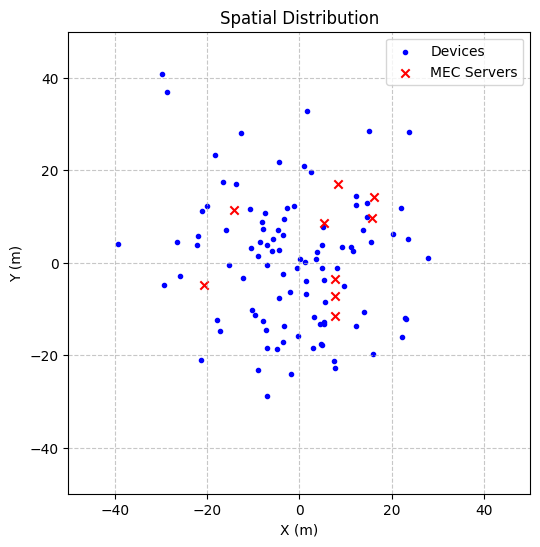


--- Simulation Summary ---
   Time_Slot  Cost_Objective  Total_Tasks_Offloaded  Avg_Device_Energy_mJ  \
0          0    4.200000e+07                    5.0              0.042569   
1          1    5.500001e+07                   17.0              0.076849   
2          2             inf                    0.0              0.130068   
3          3             inf                    0.0              0.180165   
4          4             inf                    0.0              0.227671   
5          5             inf                    0.0              0.279434   
6          6             inf                    0.0              0.322381   
7          7             inf                    0.0              0.374130   
8          8             inf                    0.0              0.419054   
9          9             inf                    0.0              0.466095   

   Total_Device_Queue_Length  Total_MEC_Queue_Length  
0                       42.0                     0.0  
1             

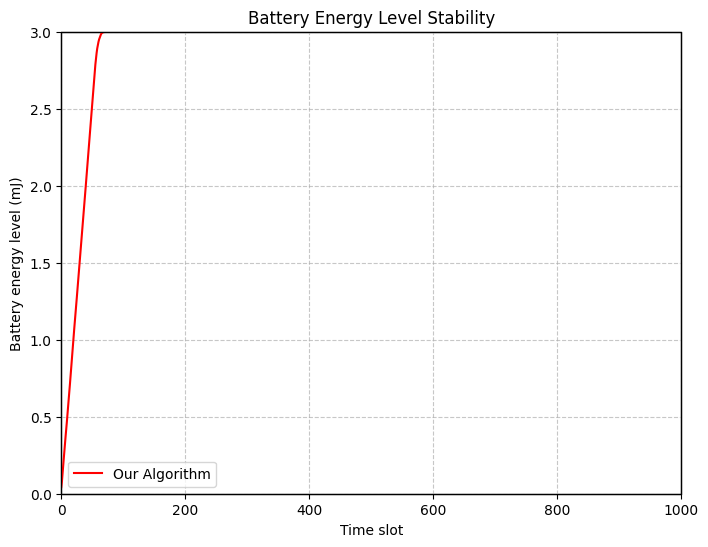

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy.special import factorial

# ====================== CONFIGURATION ======================
USE_OPTIMIZATION = True          # True = SBOA, False = SEGT only
USE_QUEUE_MODEL = True           # M/M/c queue delay in optimization

NUM_DEVICES = 100
NUM_SERVERS = 10
TIME_SLOTS = 1000

BATTERY_CAPACITY = 3.0
ENERGY_MIN = 0.02
ENERGY_MAX = 2.0
MAX_HARVEST = 0.1

TASK_SIZE_BITS = 1e5
TASK_CPU_CYCLES = 1e8
TASK_PROB = 0.5

DEVICE_CPU_FREQ = 1e9
DEVICE_CPU_POWER = 0.5
SLOT_DURATION = 0.1

MEC_CPU_FREQ = 10e9
MEC_CPU_POWER = 5.0
SERVICE_RATE = 5.0

BANDWIDTH = 10e6
NOISE_POWER = 1e-13
TX_POWER = 0.1

LEARNING_RATE = 0.05
INIT_OFFLOAD_PROB = 0.5

OPT_POP_SIZE = 50
WEIGHT_ENERGY = 1.0
WEIGHT_LATENCY = 1.0
WEIGHT_QUEUE = 1.0

# ====================== HELPER FUNCTIONS ======================
def local_energy_per_task():
    time_sec = TASK_CPU_CYCLES / DEVICE_CPU_FREQ
    return DEVICE_CPU_POWER * time_sec * 1000   # mJ

def local_delay():
    return (TASK_CPU_CYCLES / DEVICE_CPU_FREQ) / SLOT_DURATION

def offload_energy(channel_gain):
    snr = (TX_POWER * channel_gain) / NOISE_POWER
    rate = BANDWIDTH * np.log2(1 + snr)
    if rate <= 0:
        return float('inf')
    tx_time = TASK_SIZE_BITS / rate
    return TX_POWER * tx_time * 1000   # mJ

def offload_delay(channel_gain):
    snr = (TX_POWER * channel_gain) / NOISE_POWER
    rate = BANDWIDTH * np.log2(1 + snr)
    if rate <= 0:
        return float('inf')
    return (TASK_SIZE_BITS / rate) / SLOT_DURATION

def mmc_expected_waiting_time(lambda_arrival, mu, c):
    if lambda_arrival <= 0:
        return 0.0
    rho = lambda_arrival / (c * mu)
    if rho >= 1.0:
        return float('inf')
    sum_term = sum((c * rho)**i / factorial(i) for i in range(c))
    term_c = (c * rho)**c / factorial(c)
    prob_queue = term_c / ((1 - rho) * sum_term + term_c)
    return prob_queue / (c * mu - lambda_arrival)

def compute_server_arrival_rates(offload_decisions, server_choices):
    lambdas = np.zeros(NUM_SERVERS)
    for s in range(NUM_SERVERS):
        lambdas[s] = np.sum((offload_decisions == 1) & (server_choices == s))
    return lambdas

# ====================== INITIALIZATION ======================
def initialize_system():
    device_x = np.random.normal(0, 15, NUM_DEVICES)
    device_y = np.random.normal(0, 15, NUM_DEVICES)
    server_x = np.random.normal(0, 15, NUM_SERVERS)
    server_y = np.random.normal(0, 15, NUM_SERVERS)

    channel_gains = np.zeros((NUM_DEVICES, NUM_SERVERS))
    for d in range(NUM_DEVICES):
        for s in range(NUM_SERVERS):
            dist = max(np.sqrt((device_x[d]-server_x[s])**2 + (device_y[d]-server_y[s])**2), 1.0)
            path_loss = 1e-6 * (dist ** -3)
            fading = np.random.exponential(1)
            channel_gains[d, s] = path_loss * fading

    devices = {
        'x': device_x, 'y': device_y,
        'energy': np.zeros(NUM_DEVICES),
        'task_queue': np.zeros(NUM_DEVICES, dtype=int),
        'channel_gain': channel_gains,
        'offload_prob': np.full(NUM_DEVICES, INIT_OFFLOAD_PROB)
    }
    mec_servers = {
        'x': server_x, 'y': server_y,
        'queue': [deque() for _ in range(NUM_SERVERS)],
        'remaining_capacity': np.full(NUM_SERVERS, MEC_CPU_FREQ * SLOT_DURATION)
    }
    return devices, mec_servers

# ====================== STEP 1: TASK GENERATION ======================
def generate_tasks(devices):
    arrivals = np.random.binomial(1, TASK_PROB, NUM_DEVICES)
    devices['task_queue'] += arrivals
    return arrivals

# ====================== STEP 2: ENERGY HARVESTING ======================
def harvest_energy(devices):
    harvested = np.random.uniform(0, MAX_HARVEST, NUM_DEVICES)
    devices['energy'] += harvested
    devices['energy'] = np.clip(devices['energy'], 0, BATTERY_CAPACITY)
    return harvested

# ====================== STEP 3: SEGT (Behavior Layer) ======================
def segt_decision(devices):
    decisions = np.zeros(NUM_DEVICES, dtype=int)
    server_choice = np.full(NUM_DEVICES, -1, dtype=int)
    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] == 0 or devices['energy'][d] <= 0:
            continue
        if np.random.rand() < devices['offload_prob'][d]:
            gains = devices['channel_gain'][d, :]
            costs = np.array([offload_energy(g) for g in gains])
            valid = costs < float('inf')
            if np.any(valid):
                best_s = np.argmin(costs)
                if devices['energy'][d] >= costs[best_s]:
                    decisions[d] = 1
                    server_choice[d] = best_s
    return decisions, server_choice

def update_strategy(devices, decisions, rewards):
    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] > 0 or decisions[d] != -1:
            p = devices['offload_prob'][d]
            delta = LEARNING_RATE * rewards[d] * p * (1 - p)
            devices['offload_prob'][d] = np.clip(p + delta, 0.0, 1.0)

# ====================== STEP 4: M/M/c Queue Delay ======================
def compute_queue_delays(offload_vector, server_choices):
    lambdas = compute_server_arrival_rates(offload_vector, server_choices)
    delays = np.array([mmc_expected_waiting_time(lambdas[s], SERVICE_RATE, 1) for s in range(NUM_SERVERS)])
    return delays, lambdas

# ====================== STEP 5: SBOA Optimization ======================
def evaluate_solution(offload_vector, server_choices, devices, lambdas_estimated=None):
    cost = 0.0
    local_e = local_energy_per_task()
    local_d = local_delay()

    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] == 0:
            continue
        if offload_vector[d] == 1:
            s = server_choices[d]
            e_off = offload_energy(devices['channel_gain'][d, s])
            d_tx = offload_delay(devices['channel_gain'][d, s])
            if devices['energy'][d] >= e_off:
                cost += WEIGHT_ENERGY * e_off + WEIGHT_LATENCY * d_tx
            else:
                cost += 1e6
        else:
            if devices['energy'][d] >= local_e:
                cost += WEIGHT_ENERGY * local_e + WEIGHT_LATENCY * local_d
            else:
                cost += 1e6

    if USE_QUEUE_MODEL:
        if lambdas_estimated is None:
            lambdas_estimated = compute_server_arrival_rates(offload_vector, server_choices)
        for s in range(NUM_SERVERS):
            Wq = mmc_expected_waiting_time(lambdas_estimated[s], SERVICE_RATE, 1)
            cost += WEIGHT_QUEUE * Wq * lambdas_estimated[s]
    return cost

def optimize_offloading(devices):
    best_offload = np.zeros(NUM_DEVICES, dtype=int)
    best_servers = np.full(NUM_DEVICES, -1, dtype=int)
    best_cost = float('inf')

    for _ in range(OPT_POP_SIZE):
        offload = np.zeros(NUM_DEVICES, dtype=int)
        servers = np.full(NUM_DEVICES, -1, dtype=int)
        for d in range(NUM_DEVICES):
            if devices['task_queue'][d] > 0 and devices['energy'][d] > 0:
                if np.random.rand() < 0.5:
                    gains = devices['channel_gain'][d, :]
                    costs = np.array([offload_energy(g) for g in gains])
                    valid = costs < float('inf')
                    if np.any(valid):
                        best_s = np.argmin(costs)
                        if devices['energy'][d] >= costs[best_s]:
                            offload[d] = 1
                            servers[d] = best_s
        cost = evaluate_solution(offload, servers, devices)
        if cost < best_cost:
            best_cost = cost
            best_offload = offload.copy()
            best_servers = servers.copy()
    return best_offload, best_servers, best_cost

# ====================== STEP 6: EXECUTE TASKS ======================
def execute_tasks(devices, mec_servers, decisions, server_choice):
    local_e = local_energy_per_task()
    rewards = np.zeros(NUM_DEVICES)

    # Offload
    for d in range(NUM_DEVICES):
        if decisions[d] == 1 and devices['task_queue'][d] > 0:
            s = server_choice[d]
            e_cost = offload_energy(devices['channel_gain'][d, s])
            if devices['energy'][d] >= e_cost:
                devices['energy'][d] -= e_cost
                devices['task_queue'][d] -= 1
                mec_servers['queue'][s].append(TASK_CPU_CYCLES)
                rewards[d] = -e_cost

    # Local
    for d in range(NUM_DEVICES):
        if decisions[d] == 0:
            processed = 0
            while devices['task_queue'][d] > 0 and devices['energy'][d] >= local_e:
                devices['energy'][d] -= local_e
                devices['task_queue'][d] -= 1
                processed += 1
            if processed > 0:
                rewards[d] = -processed * local_e

    return rewards

# ====================== STEP 7: UPDATE SYSTEM (MEC Processing) ======================
def update_mec_servers(mec_servers):
    for s in range(NUM_SERVERS):
        capacity = mec_servers['remaining_capacity'][s]
        q = mec_servers['queue'][s]
        while q and capacity >= q[0]:
            capacity -= q.popleft()

# ====================== MAIN SIMULATION LOOP ======================
def run_simulation():
    devices, mec_servers = initialize_system()

    energy_hist = np.zeros((TIME_SLOTS, NUM_DEVICES))
    queue_hist = np.zeros((TIME_SLOTS, NUM_DEVICES))
    offload_hist = np.zeros(TIME_SLOTS)
    mec_queue_hist = np.zeros((TIME_SLOTS, NUM_SERVERS))
    prob_hist = np.zeros((TIME_SLOTS, NUM_DEVICES))
    cost_hist = np.zeros(TIME_SLOTS)

    for t in range(TIME_SLOTS):
        # Step 1: Task generation
        generate_tasks(devices)

        # Step 2: Energy harvesting
        harvest_energy(devices)

        # Step 3: SEGT (if optimization disabled, this is final decision; else used for baseline)
        segt_decisions, segt_servers = segt_decision(devices)

        # Step 4: Compute M/M/c queue delays (used inside SBOA evaluation)
        # (This is a lightweight model call, not directly used for decisions but for cost evaluation)

        # Step 5: SBOA optimization (if enabled)
        if USE_OPTIMIZATION:
            decisions, servers, best_cost = optimize_offloading(devices)
            cost_hist[t] = best_cost
            rewards = np.zeros(NUM_DEVICES)
        else:
            decisions, servers = segt_decisions, segt_servers
            cost_hist[t] = np.nan

        # Step 6: Execute tasks (local + offload)
        rewards = execute_tasks(devices, mec_servers, decisions, servers)

        # Step 7: Update system state (MEC processing, SEGT learning if applicable)
        update_mec_servers(mec_servers)
        if not USE_OPTIMIZATION:
            update_strategy(devices, decisions, rewards)

        # Record metrics
        energy_hist[t] = devices['energy']
        queue_hist[t] = devices['task_queue']
        offload_hist[t] = np.sum(decisions)
        if not USE_OPTIMIZATION:
            prob_hist[t] = devices['offload_prob']
        for s in range(NUM_SERVERS):
            mec_queue_hist[t, s] = len(mec_servers['queue'][s])

    results = {
        'energy': energy_hist,
        'device_queue': queue_hist,
        'offload_count': offload_hist,
        'mec_queue': mec_queue_hist,
        'cost_history': cost_hist,
    }
    if not USE_OPTIMIZATION:
        results['offload_prob'] = prob_hist
    return results

# ====================== PLOTTING ======================
def plot_spatial_topology(devices, mec_servers):
    plt.figure(figsize=(8,6))
    plt.scatter(devices['x'], devices['y'], c='blue', marker='.', label='Devices')
    plt.scatter(mec_servers['x'], mec_servers['y'], c='red', marker='x', label='MEC Servers')
    plt.xlim(-50,50); plt.ylim(-50,50)
    plt.xlabel('X (m)'); plt.ylabel('Y (m)')
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.7)
    plt.title('Spatial Distribution')
    plt.gca().set_aspect('equal')
    plt.show()

def plot_energy_stability(df_summary):
    plt.figure(figsize=(8,6))
    plt.plot(df_summary['Time_Slot'], df_summary['Avg_Device_Energy_mJ'],
             color='red', linewidth=1.5, label='Our Algorithm')
    plt.xlim(0, TIME_SLOTS)
    plt.ylim(0, BATTERY_CAPACITY)
    plt.xlabel('Time slot'); plt.ylabel('Battery energy level (mJ)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='lower left')
    plt.title('Battery Energy Level Stability')
    plt.gca().patch.set_edgecolor('black'); plt.gca().patch.set_linewidth(1)
    plt.show()

# ====================== MAIN ======================
if __name__ == "__main__":
    np.random.seed(42)
    devices, mec_servers = initialize_system()
    plot_spatial_topology(devices, mec_servers)

    results = run_simulation()

    df_summary = pd.DataFrame({
        'Time_Slot': np.arange(TIME_SLOTS),
        'Cost_Objective': results['cost_history'],
        'Total_Tasks_Offloaded': results['offload_count'],
        'Avg_Device_Energy_mJ': np.mean(results['energy'], axis=1),
        'Total_Device_Queue_Length': np.sum(results['device_queue'], axis=1),
        'Total_MEC_Queue_Length': np.sum(results['mec_queue'], axis=1)
    })
    if 'offload_prob' in results:
        df_summary['Avg_Offload_Prob'] = np.mean(results['offload_prob'], axis=1)

    print("\n--- Simulation Summary ---")
    print(df_summary.head(10))

    plot_energy_stability(df_summary)

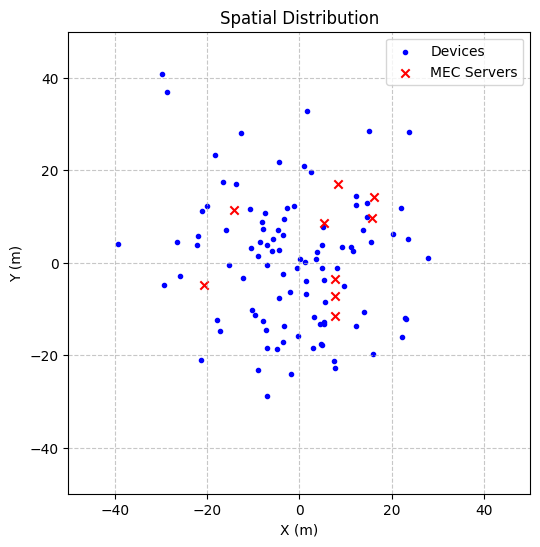


--- Simulation Summary ---
   Time_Slot  Cost_Objective  Total_Tasks_Offloaded  Avg_Device_Energy_mJ  \
0          0    4.200000e+07                    5.0              0.042569   
1          1    5.500001e+07                   17.0              0.076849   
2          2             inf                    0.0              0.130068   
3          3             inf                    0.0              0.180165   
4          4             inf                    0.0              0.227671   
5          5             inf                    0.0              0.279434   
6          6             inf                    0.0              0.322381   
7          7             inf                    0.0              0.374130   
8          8             inf                    0.0              0.419054   
9          9             inf                    0.0              0.466095   

   Total_Device_Queue_Length  Total_MEC_Queue_Length  
0                       42.0                     0.0  
1             

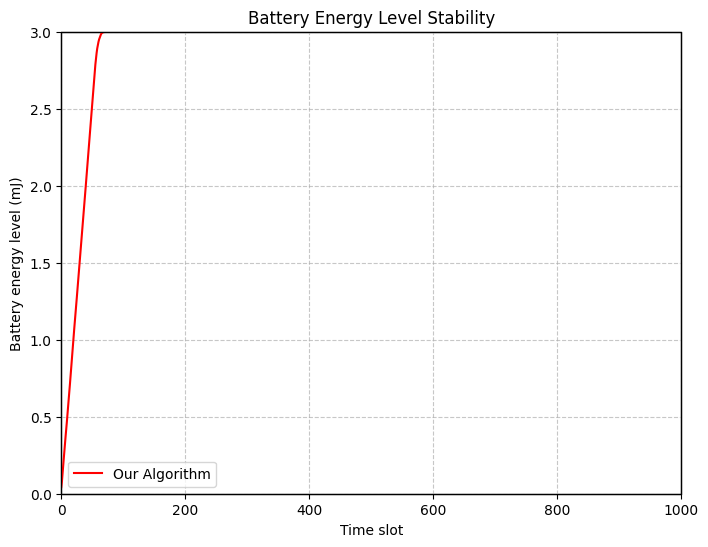

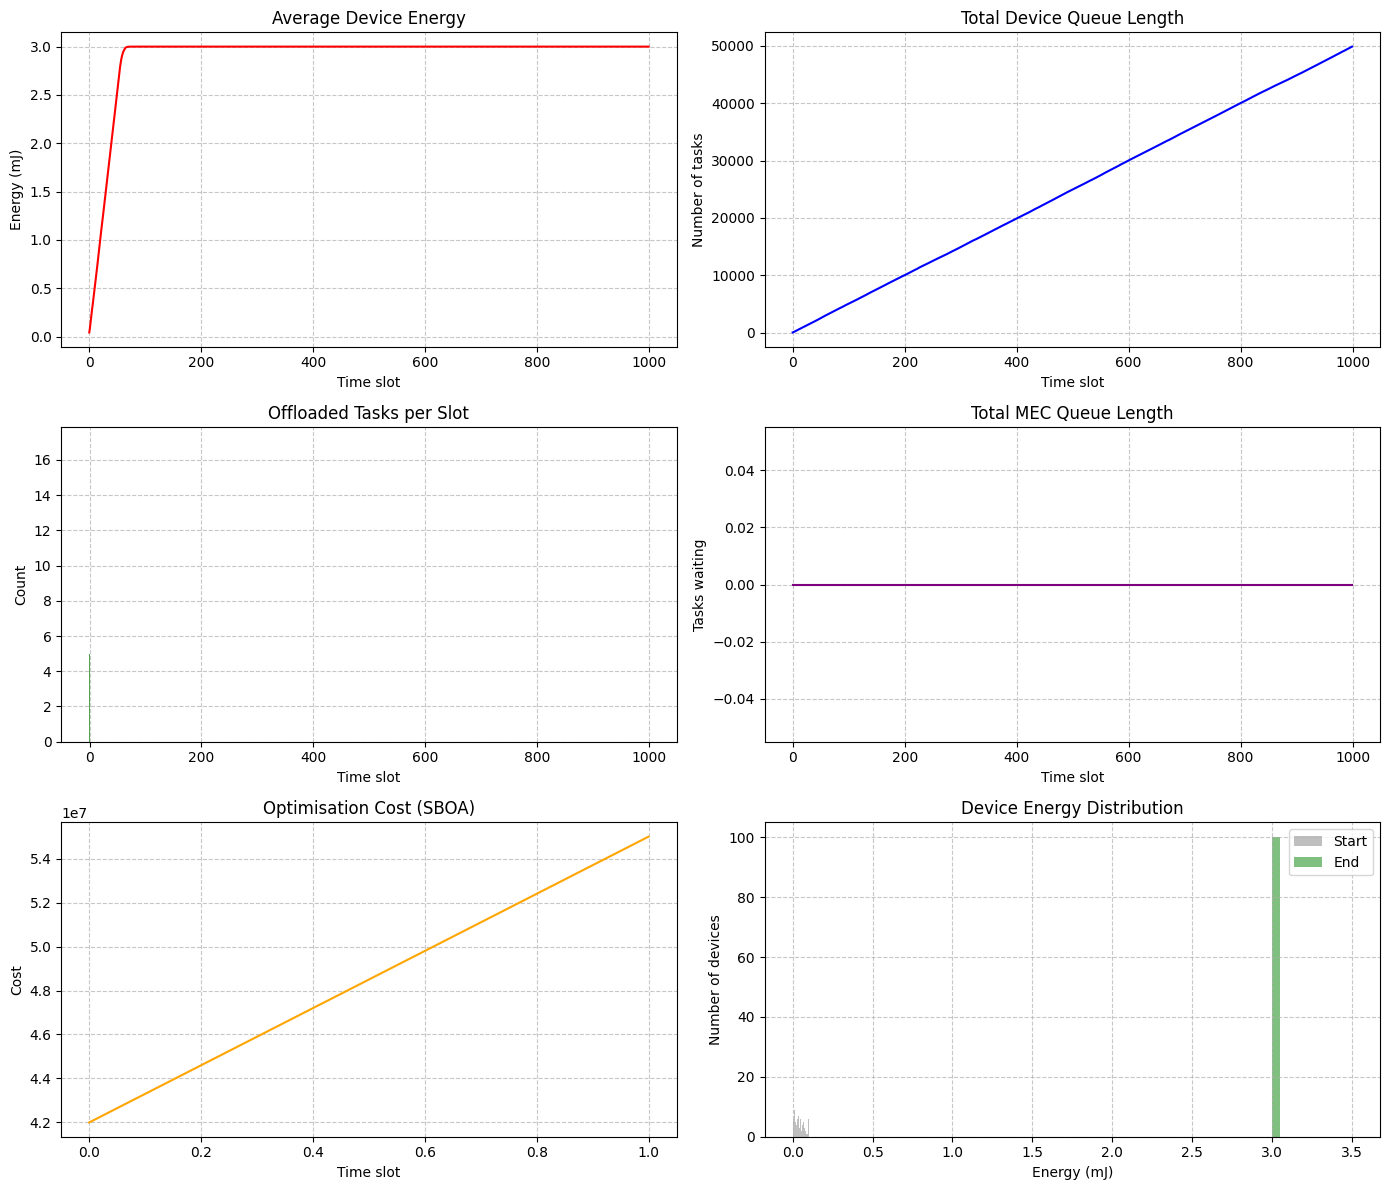

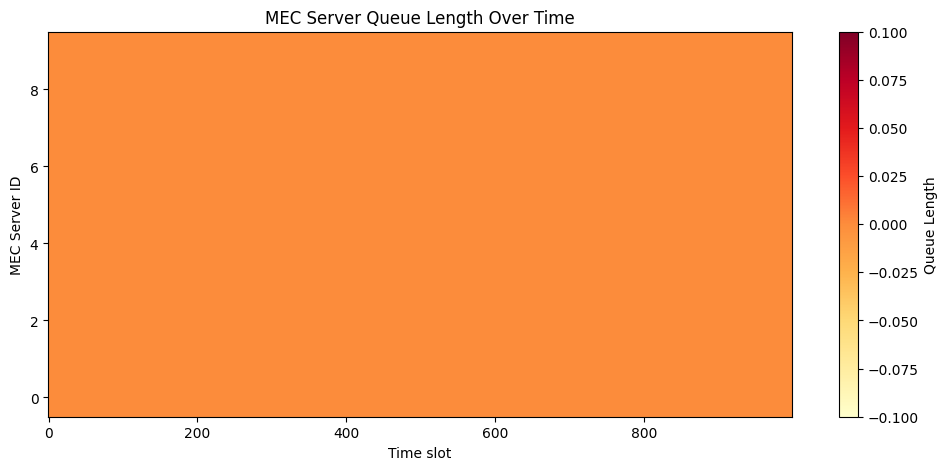

Offload probability data not available (SEGT disabled).


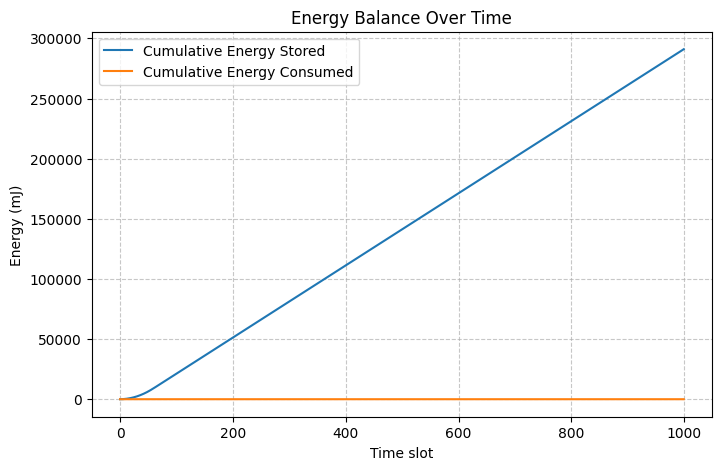

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy.special import factorial

# ====================== CONFIGURATION ======================
USE_OPTIMIZATION = True          # True = SBOA, False = SEGT only
USE_QUEUE_MODEL = True           # M/M/c queue delay in optimization

NUM_DEVICES = 100
NUM_SERVERS = 10
TIME_SLOTS = 1000

BATTERY_CAPACITY = 3.0
ENERGY_MIN = 0.02
ENERGY_MAX = 2.0
MAX_HARVEST = 0.1

TASK_SIZE_BITS = 1e5
TASK_CPU_CYCLES = 1e8
TASK_PROB = 0.5

DEVICE_CPU_FREQ = 1e9
DEVICE_CPU_POWER = 0.5
SLOT_DURATION = 0.1

MEC_CPU_FREQ = 10e9
MEC_CPU_POWER = 5.0
SERVICE_RATE = 5.0

BANDWIDTH = 10e6
NOISE_POWER = 1e-13
TX_POWER = 0.1

LEARNING_RATE = 0.05
INIT_OFFLOAD_PROB = 0.5

OPT_POP_SIZE = 50
WEIGHT_ENERGY = 1.0
WEIGHT_LATENCY = 1.0
WEIGHT_QUEUE = 1.0

# ====================== HELPER FUNCTIONS ======================
def local_energy_per_task():
    time_sec = TASK_CPU_CYCLES / DEVICE_CPU_FREQ
    return DEVICE_CPU_POWER * time_sec * 1000   # mJ

def local_delay():
    return (TASK_CPU_CYCLES / DEVICE_CPU_FREQ) / SLOT_DURATION

def offload_energy(channel_gain):
    snr = (TX_POWER * channel_gain) / NOISE_POWER
    rate = BANDWIDTH * np.log2(1 + snr)
    if rate <= 0:
        return float('inf')
    tx_time = TASK_SIZE_BITS / rate
    return TX_POWER * tx_time * 1000   # mJ

def offload_delay(channel_gain):
    snr = (TX_POWER * channel_gain) / NOISE_POWER
    rate = BANDWIDTH * np.log2(1 + snr)
    if rate <= 0:
        return float('inf')
    return (TASK_SIZE_BITS / rate) / SLOT_DURATION

def mmc_expected_waiting_time(lambda_arrival, mu, c):
    if lambda_arrival <= 0:
        return 0.0
    rho = lambda_arrival / (c * mu)
    if rho >= 1.0:
        return float('inf')
    sum_term = sum((c * rho)**i / factorial(i) for i in range(c))
    term_c = (c * rho)**c / factorial(c)
    prob_queue = term_c / ((1 - rho) * sum_term + term_c)
    return prob_queue / (c * mu - lambda_arrival)

def compute_server_arrival_rates(offload_decisions, server_choices):
    lambdas = np.zeros(NUM_SERVERS)
    for s in range(NUM_SERVERS):
        lambdas[s] = np.sum((offload_decisions == 1) & (server_choices == s))
    return lambdas

# ====================== INITIALIZATION ======================
def initialize_system():
    device_x = np.random.normal(0, 15, NUM_DEVICES)
    device_y = np.random.normal(0, 15, NUM_DEVICES)
    server_x = np.random.normal(0, 15, NUM_SERVERS)
    server_y = np.random.normal(0, 15, NUM_SERVERS)

    channel_gains = np.zeros((NUM_DEVICES, NUM_SERVERS))
    for d in range(NUM_DEVICES):
        for s in range(NUM_SERVERS):
            dist = max(np.sqrt((device_x[d]-server_x[s])**2 + (device_y[d]-server_y[s])**2), 1.0)
            path_loss = 1e-6 * (dist ** -3)
            fading = np.random.exponential(1)
            channel_gains[d, s] = path_loss * fading

    devices = {
        'x': device_x, 'y': device_y,
        'energy': np.zeros(NUM_DEVICES),
        'task_queue': np.zeros(NUM_DEVICES, dtype=int),
        'channel_gain': channel_gains,
        'offload_prob': np.full(NUM_DEVICES, INIT_OFFLOAD_PROB)
    }
    mec_servers = {
        'x': server_x, 'y': server_y,
        'queue': [deque() for _ in range(NUM_SERVERS)],
        'remaining_capacity': np.full(NUM_SERVERS, MEC_CPU_FREQ * SLOT_DURATION)
    }
    return devices, mec_servers

# ====================== STEP 1: TASK GENERATION ======================
def generate_tasks(devices):
    arrivals = np.random.binomial(1, TASK_PROB, NUM_DEVICES)
    devices['task_queue'] += arrivals
    return arrivals

# ====================== STEP 2: ENERGY HARVESTING ======================
def harvest_energy(devices):
    harvested = np.random.uniform(0, MAX_HARVEST, NUM_DEVICES)
    devices['energy'] += harvested
    devices['energy'] = np.clip(devices['energy'], 0, BATTERY_CAPACITY)
    return harvested

# ====================== STEP 3: SEGT (Behavior Layer) ======================
def segt_decision(devices):
    decisions = np.zeros(NUM_DEVICES, dtype=int)
    server_choice = np.full(NUM_DEVICES, -1, dtype=int)
    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] == 0 or devices['energy'][d] <= 0:
            continue
        if np.random.rand() < devices['offload_prob'][d]:
            gains = devices['channel_gain'][d, :]
            costs = np.array([offload_energy(g) for g in gains])
            valid = costs < float('inf')
            if np.any(valid):
                best_s = np.argmin(costs)
                if devices['energy'][d] >= costs[best_s]:
                    decisions[d] = 1
                    server_choice[d] = best_s
    return decisions, server_choice

def update_strategy(devices, decisions, rewards):
    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] > 0 or decisions[d] != -1:
            p = devices['offload_prob'][d]
            delta = LEARNING_RATE * rewards[d] * p * (1 - p)
            devices['offload_prob'][d] = np.clip(p + delta, 0.0, 1.0)

# ====================== STEP 4: M/M/c Queue Delay ======================
def compute_queue_delays(offload_vector, server_choices):
    lambdas = compute_server_arrival_rates(offload_vector, server_choices)
    delays = np.array([mmc_expected_waiting_time(lambdas[s], SERVICE_RATE, 1) for s in range(NUM_SERVERS)])
    return delays, lambdas

# ====================== STEP 5: SBOA Optimization ======================
def evaluate_solution(offload_vector, server_choices, devices, lambdas_estimated=None):
    cost = 0.0
    local_e = local_energy_per_task()
    local_d = local_delay()

    for d in range(NUM_DEVICES):
        if devices['task_queue'][d] == 0:
            continue
        if offload_vector[d] == 1:
            s = server_choices[d]
            e_off = offload_energy(devices['channel_gain'][d, s])
            d_tx = offload_delay(devices['channel_gain'][d, s])
            if devices['energy'][d] >= e_off:
                cost += WEIGHT_ENERGY * e_off + WEIGHT_LATENCY * d_tx
            else:
                cost += 1e6
        else:
            if devices['energy'][d] >= local_e:
                cost += WEIGHT_ENERGY * local_e + WEIGHT_LATENCY * local_d
            else:
                cost += 1e6

    if USE_QUEUE_MODEL:
        if lambdas_estimated is None:
            lambdas_estimated = compute_server_arrival_rates(offload_vector, server_choices)
        for s in range(NUM_SERVERS):
            Wq = mmc_expected_waiting_time(lambdas_estimated[s], SERVICE_RATE, 1)
            cost += WEIGHT_QUEUE * Wq * lambdas_estimated[s]
    return cost

def optimize_offloading(devices):
    best_offload = np.zeros(NUM_DEVICES, dtype=int)
    best_servers = np.full(NUM_DEVICES, -1, dtype=int)
    best_cost = float('inf')

    for _ in range(OPT_POP_SIZE):
        offload = np.zeros(NUM_DEVICES, dtype=int)
        servers = np.full(NUM_DEVICES, -1, dtype=int)
        for d in range(NUM_DEVICES):
            if devices['task_queue'][d] > 0 and devices['energy'][d] > 0:
                if np.random.rand() < 0.5:
                    gains = devices['channel_gain'][d, :]
                    costs = np.array([offload_energy(g) for g in gains])
                    valid = costs < float('inf')
                    if np.any(valid):
                        best_s = np.argmin(costs)
                        if devices['energy'][d] >= costs[best_s]:
                            offload[d] = 1
                            servers[d] = best_s
        cost = evaluate_solution(offload, servers, devices)
        if cost < best_cost:
            best_cost = cost
            best_offload = offload.copy()
            best_servers = servers.copy()
    return best_offload, best_servers, best_cost

# ====================== STEP 6: EXECUTE TASKS ======================
def execute_tasks(devices, mec_servers, decisions, server_choice):
    local_e = local_energy_per_task()
    rewards = np.zeros(NUM_DEVICES)

    # Offload
    for d in range(NUM_DEVICES):
        if decisions[d] == 1 and devices['task_queue'][d] > 0:
            s = server_choice[d]
            e_cost = offload_energy(devices['channel_gain'][d, s])
            if devices['energy'][d] >= e_cost:
                devices['energy'][d] -= e_cost
                devices['task_queue'][d] -= 1
                mec_servers['queue'][s].append(TASK_CPU_CYCLES)
                rewards[d] = -e_cost

    # Local
    for d in range(NUM_DEVICES):
        if decisions[d] == 0:
            processed = 0
            while devices['task_queue'][d] > 0 and devices['energy'][d] >= local_e:
                devices['energy'][d] -= local_e
                devices['task_queue'][d] -= 1
                processed += 1
            if processed > 0:
                rewards[d] = -processed * local_e

    return rewards

# ====================== STEP 7: UPDATE SYSTEM (MEC Processing) ======================
def update_mec_servers(mec_servers):
    for s in range(NUM_SERVERS):
        capacity = mec_servers['remaining_capacity'][s]
        q = mec_servers['queue'][s]
        while q and capacity >= q[0]:
            capacity -= q.popleft()

# ====================== MAIN SIMULATION LOOP ======================
def run_simulation():
    devices, mec_servers = initialize_system()

    energy_hist = np.zeros((TIME_SLOTS, NUM_DEVICES))
    queue_hist = np.zeros((TIME_SLOTS, NUM_DEVICES))
    offload_hist = np.zeros(TIME_SLOTS)
    mec_queue_hist = np.zeros((TIME_SLOTS, NUM_SERVERS))
    prob_hist = np.zeros((TIME_SLOTS, NUM_DEVICES))
    cost_hist = np.zeros(TIME_SLOTS)

    for t in range(TIME_SLOTS):
        # Step 1: Task generation
        generate_tasks(devices)

        # Step 2: Energy harvesting
        harvest_energy(devices)

        # Step 3: SEGT (if optimization disabled, this is final decision; else used for baseline)
        segt_decisions, segt_servers = segt_decision(devices)

        # Step 4: Compute M/M/c queue delays (used inside SBOA evaluation)
        # (This is a lightweight model call, not directly used for decisions but for cost evaluation)

        # Step 5: SBOA optimization (if enabled)
        if USE_OPTIMIZATION:
            decisions, servers, best_cost = optimize_offloading(devices)
            cost_hist[t] = best_cost
            rewards = np.zeros(NUM_DEVICES)
        else:
            decisions, servers = segt_decisions, segt_servers
            cost_hist[t] = np.nan

        # Step 6: Execute tasks (local + offload)
        rewards = execute_tasks(devices, mec_servers, decisions, servers)

        # Step 7: Update system state (MEC processing, SEGT learning if applicable)
        update_mec_servers(mec_servers)
        if not USE_OPTIMIZATION:
            update_strategy(devices, decisions, rewards)

        # Record metrics
        energy_hist[t] = devices['energy']
        queue_hist[t] = devices['task_queue']
        offload_hist[t] = np.sum(decisions)
        if not USE_OPTIMIZATION:
            prob_hist[t] = devices['offload_prob']
        for s in range(NUM_SERVERS):
            mec_queue_hist[t, s] = len(mec_servers['queue'][s])

    results = {
        'energy': energy_hist,
        'device_queue': queue_hist,
        'offload_count': offload_hist,
        'mec_queue': mec_queue_hist,
        'cost_history': cost_hist,
    }
    if not USE_OPTIMIZATION:
        results['offload_prob'] = prob_hist
    return results

# ====================== PLOTTING ======================
def plot_spatial_topology(devices, mec_servers):
    plt.figure(figsize=(8,6))
    plt.scatter(devices['x'], devices['y'], c='blue', marker='.', label='Devices')
    plt.scatter(mec_servers['x'], mec_servers['y'], c='red', marker='x', label='MEC Servers')
    plt.xlim(-50,50); plt.ylim(-50,50)
    plt.xlabel('X (m)'); plt.ylabel('Y (m)')
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.7)
    plt.title('Spatial Distribution')
    plt.gca().set_aspect('equal')
    plt.show()

def plot_energy_stability(df_summary):
    plt.figure(figsize=(8,6))
    plt.plot(df_summary['Time_Slot'], df_summary['Avg_Device_Energy_mJ'],
             color='red', linewidth=1.5, label='Our Algorithm')
    plt.xlim(0, TIME_SLOTS)
    plt.ylim(0, BATTERY_CAPACITY)
    plt.xlabel('Time slot'); plt.ylabel('Battery energy level (mJ)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='lower left')
    plt.title('Battery Energy Level Stability')
    plt.gca().patch.set_edgecolor('black'); plt.gca().patch.set_linewidth(1)
    plt.show()


def plot_comprehensive_results(results, df_summary):
    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    
    # 1. Average Device Energy
    axes[0,0].plot(df_summary['Time_Slot'], df_summary['Avg_Device_Energy_mJ'], color='red')
    axes[0,0].set_title('Average Device Energy')
    axes[0,0].set_xlabel('Time slot')
    axes[0,0].set_ylabel('Energy (mJ)')
    axes[0,0].grid(True, linestyle='--', alpha=0.7)
    
    # 2. Total Device Queue Length
    axes[0,1].plot(df_summary['Time_Slot'], df_summary['Total_Device_Queue_Length'], color='blue')
    axes[0,1].set_title('Total Device Queue Length')
    axes[0,1].set_xlabel('Time slot')
    axes[0,1].set_ylabel('Number of tasks')
    axes[0,1].grid(True, linestyle='--', alpha=0.7)
    
    # 3. Offloaded Tasks per Slot
    axes[1,0].bar(df_summary['Time_Slot'], df_summary['Total_Tasks_Offloaded'], width=1.0, color='green', alpha=0.7)
    axes[1,0].set_title('Offloaded Tasks per Slot')
    axes[1,0].set_xlabel('Time slot')
    axes[1,0].set_ylabel('Count')
    axes[1,0].grid(True, linestyle='--', alpha=0.7)
    
    # 4. Total MEC Queue Length
    axes[1,1].plot(df_summary['Time_Slot'], df_summary['Total_MEC_Queue_Length'], color='purple')
    axes[1,1].set_title('Total MEC Queue Length')
    axes[1,1].set_xlabel('Time slot')
    axes[1,1].set_ylabel('Tasks waiting')
    axes[1,1].grid(True, linestyle='--', alpha=0.7)
    
    # 5. Cost Objective (if SBOA)
    axes[2,0].plot(df_summary['Time_Slot'], df_summary['Cost_Objective'], color='orange')
    axes[2,0].set_title('Optimisation Cost (SBOA)')
    axes[2,0].set_xlabel('Time slot')
    axes[2,0].set_ylabel('Cost')
    axes[2,0].grid(True, linestyle='--', alpha=0.7)
    
    # 6. Energy Distribution (Start vs End)
    start_energy = results['energy'][0]
    end_energy = results['energy'][-1]
    axes[2,1].hist(start_energy, bins=20, alpha=0.5, label='Start', color='gray')
    axes[2,1].hist(end_energy, bins=20, alpha=0.5, label='End', color='green')
    axes[2,1].set_title('Device Energy Distribution')
    axes[2,1].set_xlabel('Energy (mJ)')
    axes[2,1].set_ylabel('Number of devices')
    axes[2,1].legend()
    axes[2,1].grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

def plot_server_heatmap(results):
    plt.figure(figsize=(12, 5))
    plt.imshow(results['mec_queue'].T, aspect='auto', cmap='YlOrRd', origin='lower')
    plt.colorbar(label='Queue Length')
    plt.xlabel('Time slot')
    plt.ylabel('MEC Server ID')
    plt.title('MEC Server Queue Length Over Time')
    plt.show()


def plot_offload_probabilities(results):
    if 'offload_prob' not in results:
        print("Offload probability data not available (SEGT disabled).")
        return
    plt.figure(figsize=(10, 5))
    for d in range(min(10, NUM_DEVICES)):   # plot first 10 devices
        plt.plot(results['offload_prob'][:, d], alpha=0.6, label=f'Dev {d}')
    plt.plot(np.mean(results['offload_prob'], axis=1), 'k--', linewidth=2, label='Average')
    plt.xlabel('Time slot')
    plt.ylabel('Offload Probability')
    plt.title('SEGT Strategy Evolution')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()


def plot_energy_balance(results):
    energy_consumed = np.zeros(TIME_SLOTS)
    for t in range(1, TIME_SLOTS):
        energy_consumed[t] = energy_consumed[t-1] + np.sum(np.maximum(0, results['energy'][t-1] - results['energy'][t]))
    plt.figure(figsize=(8,5))
    plt.plot(np.cumsum(np.sum(results['energy'], axis=1)), label='Cumulative Energy Stored')
    plt.plot(energy_consumed, label='Cumulative Energy Consumed')
    plt.xlabel('Time slot')
    plt.ylabel('Energy (mJ)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.title('Energy Balance Over Time')
    plt.show()
# ====================== MAIN ======================
if __name__ == "__main__":
    np.random.seed(42)

    devices, mec_servers = initialize_system()
    plot_spatial_topology(devices, mec_servers)

    results = run_simulation()

    df_summary = pd.DataFrame({
        'Time_Slot': np.arange(TIME_SLOTS),
        'Cost_Objective': results['cost_history'],
        'Total_Tasks_Offloaded': results['offload_count'],
        'Avg_Device_Energy_mJ': np.mean(results['energy'], axis=1),
        'Total_Device_Queue_Length': np.sum(results['device_queue'], axis=1),
        'Total_MEC_Queue_Length': np.sum(results['mec_queue'], axis=1)
    })
    if 'offload_prob' in results:
        df_summary['Avg_Offload_Prob'] = np.mean(results['offload_prob'], axis=1)

    print("\n--- Simulation Summary ---")
    print(df_summary.head(10))

    # ---------- ADD PLOTTING FUNCTION CALLS HERE ----------
    plot_energy_stability(df_summary)          # your existing energy plot
    plot_comprehensive_results(results, df_summary)   # multi-panel overview
    plot_server_heatmap(results)                     # server queue heatmap
    plot_offload_probabilities(results)              # SEGT evolution (if enabled)
    plot_energy_balance(results)                     # cumulative energy balance
    # -----------------------------------------------------

In [4]:
def compute_avg_latency(results):
    total_tasks = np.sum(results['offload_count']) + np.sum(results['device_queue'])
    if total_tasks == 0:
        return 0
    # Approximation: queue length as delay proxy
    avg_delay = np.mean(np.sum(results['device_queue'], axis=1))
    return avg_delay


def compute_total_energy(results):
    energy_start = np.sum(results['energy'][0])
    energy_end = np.sum(results['energy'][-1])
    return energy_start - energy_end


def compute_throughput(results):
    total_offloaded = np.sum(results['offload_count'])
    return total_offloaded / TIME_SLOTS


def compute_drop_rate(results):
    remaining_tasks = np.sum(results['device_queue'][-1])
    total_generated = np.sum(results['device_queue']) + remaining_tasks
    if total_generated == 0:
        return 0
    return remaining_tasks / total_generated


def compute_mec_utilization(results):
    avg_queue = np.mean(results['mec_queue'])
    return avg_queue / NUM_SERVERS


def compute_offloading_ratio(results):
    total_offloaded = np.sum(results['offload_count'])
    total_tasks = total_offloaded + np.sum(results['device_queue'])
    if total_tasks == 0:
        return 0
    return total_offloaded / total_tasks


def print_performance_metrics(results):
    print("\n--- Performance Metrics ---")

    print(f"Average Latency          : {compute_avg_latency(results):.4f}")
    print(f"Total Energy Consumed    : {compute_total_energy(results):.4f} mJ")
    print(f"Throughput (tasks/slot) : {compute_throughput(results):.4f}")
    print(f"Drop Rate               : {compute_drop_rate(results):.4f}")


print_performance_metrics(results)


--- Performance Metrics ---
Average Latency          : 24956.7110
Total Energy Consumed    : -295.7431 mJ
Throughput (tasks/slot) : 0.0220
Drop Rate               : 0.0020
